Epoch 1/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0220 - val_loss: 0.0039
Epoch 2/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0042 - val_loss: 0.0035
Epoch 3/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0038 - val_loss: 0.0032
Epoch 4/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0034 - val_loss: 0.0029
Epoch 5/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0032 - val_loss: 0.0029
Epoch 6/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0031 - val_loss: 0.0027
Epoch 7/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0030 - val_loss: 0.0026
Epoch 8/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0030 - val_loss: 0.0029
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
MAE: 3.5077746999102666
RMSE: 4.317402107625171


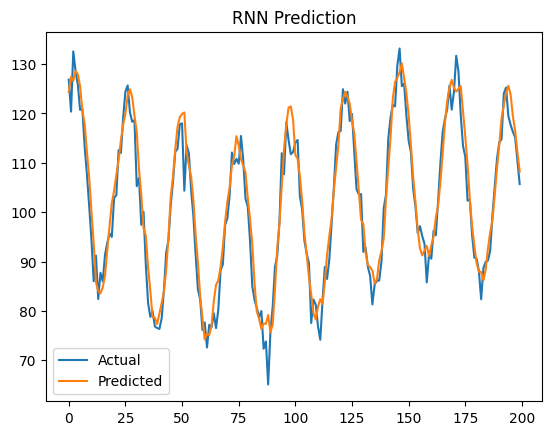

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

t = np.arange(3000)
series = (100 + 20*np.sin(2*np.pi*t/24)
          + 8*np.sin(2*np.pi*t/168)
          + np.random.normal(0, 3, len(t)))

scaler = MinMaxScaler()
z = scaler.fit_transform(series.reshape(-1, 1)).ravel()

window = 24
X = np.array([z[i:i+window] for i in range(len(z)-window)])
y = z[window:]

cut = int(0.8 * len(X))
Xtr, Xte = X[:cut], X[cut:]
ytr, yte = y[:cut], y[cut:]

Xtr = Xtr[:, :, None]
Xte = Xte[:, :, None]

model = tf.keras.Sequential([
    tf.keras.layers.Input((window, 1)),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer="adam", loss="mse")

model.fit(Xtr, ytr, epochs=8,
          validation_split=0.1, batch_size=32)

pred = model.predict(Xte).ravel()

actual = scaler.inverse_transform(
    yte.reshape(-1, 1)).ravel()

predicted = scaler.inverse_transform(
    pred.reshape(-1, 1)).ravel()

print("MAE:", mean_absolute_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))

plt.plot(actual[:200], label="Actual")
plt.plot(predicted[:200], label="Predicted")
plt.legend()
plt.title("RNN Prediction")
plt.show()
